# Solutions to the exercises of Chapter 5

Sample solutions for [Chapter 5, The approximation method](../../notebooks/part1_principle/05_approximation_method.ipynb).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from scipy.integrate import solve_bvp

try:
    import onsager as on
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import onsager as on

on.use_style()

## Exercise 1. An exponential profile

For $c = c_0e^{-x/\ell}$, with $u = x/\ell$: $\partial c/\partial t = c_0\,u\,e^{-u}\,\dot\ell/\ell$,
and the flux that vanishes far away is

$$ J = \int_x^\infty\frac{\partial c}{\partial t}\,dx' = c_0\,\dot\ell\,(1 + u)\,e^{-u} . $$

Then

$$ \Phi = \frac\zeta2\int_0^\infty\frac{J^2}{c}\,dx = \frac{\zeta c_0\,\ell\,\dot\ell^2}{2}\int_0^\infty (1 + u)^2e^{-u}\,du = \frac52\,\zeta c_0\,\ell\,\dot\ell^2 . $$

For the free energy, with $s = c/c_0 = e^{-u}$, the integrand $s\ln s - s + 1$
differs from its value in the empty region, 1, by $-(1 + u)e^{-u}$, whose integral
is $-2$. So $A = {\rm const} - 2k_BTc_0\,\ell$ and $\dot A = -2k_BTc_0\,\dot\ell$.
Minimising, $5\zeta c_0\,\ell\dot\ell = 2k_BTc_0$:

$$ \ell^2 = \tfrac45Dt , \qquad M = c_0\ell = 0.894\,c_0\sqrt{Dt} , $$

which is 20.7 % below the exact $1.128\,c_0\sqrt{Dt}$.

In [2]:
x = np.linspace(0, 40, 400001)
Z = on.friction_matrix_1d(x, np.exp(-x), [x * np.exp(-x)])       # ell = 1: dc/d(ell) = x exp(-x)
print(f"friction coefficient / (zeta c0 ell): {Z[0, 0]:.6f}   (5 expected)")
lam = math.sqrt(4 / 5)
exact = 2 / math.sqrt(math.pi)
print(f"uptake: {lam:.4f}   exact: {exact:.4f}   error: {100 * (lam / exact - 1):+.1f} %")
print(f"wall flux from the gradient: {1 / lam:.3f}   from the rate of uptake: {lam / 2:.3f}   exact: {1 / math.sqrt(math.pi):.3f}")
print(f"Onsager-Machlup function b = 5 lam^3/8 - lam + 1/(2 lam) = {5 * lam**3 / 8 - lam + 1 / (2 * lam):.4f}"
      "   (n = 2: 0.0746; n = 3: 0.0140)")

friction coefficient / (zeta c0 ell): 5.000000   (5 expected)
uptake: 0.8944   exact: 1.1284   error: -20.7 %
wall flux from the gradient: 1.118   from the rate of uptake: 0.447   exact: 0.564
Onsager-Machlup function b = 5 lam^3/8 - lam + 1/(2 lam) = 0.1118   (n = 2: 0.0746; n = 3: 0.0140)


The exponential has a tail, like the exact solution, but the tail is far too
heavy: the exact profile falls off as a Gaussian, $e^{-x^2/4Dt}$, the trial only as
$e^{-x/\ell}$. Moving solute out to large distances is expensive (the factor
$(1 + u)^2$ in the dissipation), so the principle keeps $\ell$ small, and the uptake
comes out low. The diagnostic of Section 5.3 gives a clear warning: the two
estimates of the wall flux, 1.12 and 0.45, differ by a factor of 2.5. So does the
function $b$ of Section 5.5, here $\tfrac58\lambda^3 - \lambda + 1/2\lambda = 0.112$,
eight times its value for $n = 3$.

The straight line is wrong at the front; the exponential is wrong everywhere
except at the wall. A profile with a finite range and a smooth front is the better
family for this problem.

## Exercise 2. A case where the trial is exact

For $c = N(2\pi\sigma^2)^{-1/2}e^{-x^2/2\sigma^2}$, a change of $\sigma$ stretches the
profile uniformly: the particle at $x$ moves with velocity $v = x\dot\sigma/\sigma$.
(Check: $\partial_t c = -\partial_x(cv)$.) Then

$$ \Phi = \frac\zeta2\int c\,v^2dx = \frac{\zeta\dot\sigma^2}{2\sigma^2}\int c\,x^2dx = \tfrac12\zeta N\dot\sigma^2 , $$

$$ A = k_BT\int c\,(\ln c - 1)\,dx = -Nk_BT\ln\sigma + {\rm const} . $$

Minimising $\Phi + \dot A$: $\zeta N\dot\sigma = Nk_BT/\sigma$, so
$\sigma\dot\sigma = D$ and $\sigma^2 = \sigma_0^2 + 2Dt$. This is exact.

It is exact because the exact solution of the diffusion equation with a Gaussian
initial condition is a Gaussian at all times: the true path never leaves the
family. The same was seen for the tube in Chapter 1. A trial family gives the exact
answer whenever it contains the exact path, and only then.

In [3]:
x, sigma, N, zeta, kT = sp.symbols("x sigma N zeta k_BT", positive=True)
sdot = sp.symbols("sigmadot")
c = N / sp.sqrt(2 * sp.pi * sigma**2) * sp.exp(-x**2 / (2 * sigma**2))
v = x * sdot / sigma
print("conservation residual:", sp.simplify(sp.diff(c, sigma) * sdot + sp.diff(c * v, x)))
Phi = sp.simplify(sp.integrate(zeta * c * v**2 / 2, (x, -sp.oo, sp.oo)))
A = sp.simplify(sp.integrate(kT * c * (sp.log(c) - 1), (x, -sp.oo, sp.oo)))
print("Phi =", Phi, "    dA/dsigma =", sp.simplify(sp.diff(A, sigma)))
print("sigmadot =", on.kinetic_equations(A, Phi, [sigma], [sdot])[sdot])

conservation residual: 0


Phi = N*sigmadot**2*zeta/2     dA/dsigma = -N*k_BT/sigma


sigmadot = k_BT/(sigma*zeta)


## Exercise 3. The quadratic profile by hand

For $c = c_0s^2$ with $s = 1 - x/\ell$: $\partial c/\partial t = 2c_0\,s\,(1 - s)\,\dot\ell/\ell$,
and integrating from $x$ to the front,

$$ J = c_0\,\dot\ell\int_0^s 2\sigma(1 - \sigma)\,d\sigma = c_0\,\dot\ell\;s^2\Big(1 - \frac{2s}{3}\Big) . $$

$$ \Phi = \frac{\zeta c_0\,\ell\,\dot\ell^2}{2}\int_0^1 s^2\Big(1 - \frac{2s}{3}\Big)^2ds
        = \frac{\zeta c_0\,\ell\,\dot\ell^2}{2}\Big(\frac13 - \frac13 + \frac{4}{45}\Big)
        = \frac{\zeta c_0\,\ell\,\dot\ell^2}{2}\cdot\frac{4}{45} . $$

For the free energy, $\int_0^1 (s^2 - s^2\ln s^2)\,ds = \tfrac13 + \tfrac29 = \tfrac59$, so
$\dot A = -\tfrac59k_BTc_0\,\dot\ell$. Minimising,

$$ \frac{4}{45}\,\ell\dot\ell = \frac59D \quad\Longrightarrow\quad \ell^2 = \frac{25}{2}Dt , \qquad \lambda^2 = \frac{25}{2} , $$

and $M = c_0\ell/3 = 1.179\,c_0\sqrt{Dt}$.

In [4]:
s = sp.symbols("s", positive=True)
J = sp.integrate(2 * s * (1 - s), (s, 0, s))
I2 = sp.integrate(J**2 / s**2, (s, 0, 1))
g2 = sp.integrate(s**2 - s**2 * sp.log(s**2), (s, 0, 1))
print("J / (c0 ldot) =", sp.factor(J), "   I =", I2, "   g =", g2, "   lambda^2 =", 2 * g2 / I2)

J / (c0 ldot) = -s**2*(2*s - 3)/3    I = 4/45    g = 5/9    lambda^2 = 25/2


## Exercise 4. Repelling particles

The wall is in contact with a reservoir at $c_0$, whose chemical potential is now
$\mu_0 = k_BT(\ln c_0 + Bc_0)$. The free energy of solution plus reservoir, with a
constant added so that it vanishes at $c = c_0$, is

$$ \frac{f - \mu_0c}{k_BT} + {\rm const} = c\ln\frac{c}{c_0} - c + c_0 + \tfrac12B\,(c - c_0)^2 . $$

For the straight line $c = c_0s$, with $\beta = Bc_0$, the integral over the profile
is $c_0\ell\,(\tfrac14 + \tfrac16\beta)$ and the empty region contributes
$c_0\,(1 + \tfrac12\beta)$ per unit length, so

$$ A = {\rm const} - k_BTc_0\,\ell\,\Big(\frac34 + \frac\beta3\Big) . $$

The dissipation function depends only on the profile and is unchanged,
$\Phi = \tfrac{11}{96}\zeta c_0\,\ell\dot\ell^2$. Minimising,

$$ \ell^2 = \frac{72}{11}\Big(1 + \frac{4\beta}{9}\Big)Dt , \qquad
   M = \frac{c_0\ell}{2} = 1.279\sqrt{1 + \tfrac49Bc_0}\;\,c_0\sqrt{Dt} . $$

The $\sqrt t$ law survives, because the problem still has no length scale of its
own, and repulsion increases the uptake.

For comparison, the diffusion equation $\partial_tc = \partial_x[D(1 + Bc)\,\partial_xc]$
has a similarity solution $c(\xi)$, $\xi = x/\sqrt{Dt}$, which satisfies
$-\tfrac12\xi\,dc/d\xi = d[(1 + \beta c)\,dc/d\xi]/d\xi$ with $c(0) = 1$ and
$c(\infty) = 0$ (in units of $c_0$). The cell solves this boundary-value problem.

  B c0    variational    numerical     error
   0.0      1.2792        1.1284     +13.4 %
   0.5      1.4142        1.2948      +9.2 %
   1.0      1.5374        1.4412      +6.7 %
   2.0      1.7581        1.6952      +3.7 %


   4.0      2.1320        2.1116      +1.0 %


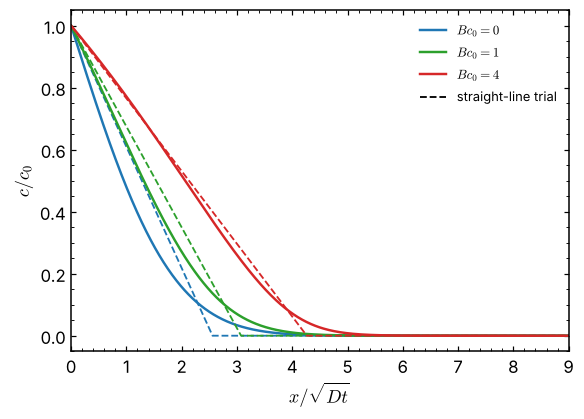

In [5]:
def similarity_uptake(beta):
    """M / (c0 sqrt(D t)) from the similarity solution; y = [c, (1 + beta c) dc/dxi]."""
    rhs = lambda xi, y: [y[1] / (1 + beta * y[0]), -xi / 2 * y[1] / (1 + beta * y[0])]
    bc = lambda ya, yb: [ya[0] - 1, yb[0]]
    xi = np.linspace(0, 14 * math.sqrt(1 + beta), 2001)
    guess = np.vstack([np.exp(-xi / math.sqrt(1 + beta)), -np.exp(-xi)])
    sol = solve_bvp(rhs, bc, xi, guess, tol=1e-8, max_nodes=200000)
    assert sol.success
    return np.trapezoid(sol.sol(xi)[0], xi), xi, sol.sol(xi)[0]


print("  B c0    variational    numerical     error")
profiles = {}
for beta in (0.0, 0.5, 1.0, 2.0, 4.0):
    M_num, xi, cprof = similarity_uptake(beta)
    M_var = 0.5 * math.sqrt(72 / 11 * (1 + 4 * beta / 9))
    profiles[beta] = (xi, cprof)
    print(f"  {beta:4.1f}      {M_var:.4f}        {M_num:.4f}     {100 * (M_var / M_num - 1):+5.1f} %")

fig, ax = plt.subplots(figsize=(5.2, 3.7))
for beta, col in ((0.0, "C0"), (1.0, "C2"), (4.0, "C3")):
    xi, cprof = profiles[beta]
    lam = math.sqrt(72 / 11 * (1 + 4 * beta / 9))
    ax.plot(xi, cprof, color=col, label=rf"$Bc_0 = {beta:g}$")
    ax.plot([0, lam, 9], [1, 0, 0], "--", color=col, lw=1.2)
ax.plot([], [], "k--", lw=1.2, label="straight-line trial")
ax.set_xlim(0, 9); ax.set_xlabel(r"$x/\sqrt{Dt}$"); ax.set_ylabel("$c/c_0$"); ax.legend(fontsize=8.5)
plt.show()

The straight line overestimates the uptake by 13 % for an ideal solution, by 7 %
for $Bc_0 = 1$ and by 1 % for $Bc_0 = 4$. The trial improves as the repulsion grows,
and the figure shows why: when the diffusion coefficient increases with
concentration, the profile is flattened where it is dense and steepened at its
edge, and the exact solution itself approaches a straight line with a front. A
trial family that is poor for one material can be good for another.